In [1]:
# Import production deployment, caching, serialization, and telemetry libraries
import os
import time
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress OpenMP multi-threading runtime warnings
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


In [2]:
# Load the clothing reviews dataset for production benchmarking
dataset_file = "womens_clothing_classification_dataset.csv"
if not os.path.exists(dataset_file):
    dataset_file = os.path.join("05-11-2026", "Task 3", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(dataset_file)
print(f"Dataset successfully verified for production deployment: {df.shape[0]} rows, {df.shape[1]} columns.")
display(df[['Clothing ID', 'Department Name', 'Rating', 'Recommended IND']].head())


Dataset successfully verified for production deployment: 23486 rows, 23 columns.


,Clothing ID,Department Name,Rating,Recommended IND
0,767,Intimate,4,1
1,1080,Dresses,5,1
2,1077,Dresses,3,0
3,1049,Bottoms,5,1
4,847,Tops,5,1


In [3]:
# Load and display model serialization benchmark metrics (Pickle vs Joblib)
serialization_csv = "model_serialization_benchmark_metrics.csv"
if not os.path.exists(serialization_csv):
    serialization_csv = os.path.join("05-11-2026", "Task 3", "model_serialization_benchmark_metrics.csv")

df_serial_results = pd.read_csv(serialization_csv)
print("Model Serialization Benchmark: Deserialization Latency & Disk Storage Footprint:")
display(df_serial_results)


Model Serialization Benchmark: Deserialization Latency & Disk Storage Footprint:


,Model_Architecture,Protocol,File_Size_KB,Mean_Load_Time_ms,Std_Load_Time_ms,Speedup_vs_Pickle,Storage_Compression_Pct
0,XGBoost_Optimal,Standard Pickle,486.03,6.66,0.87,1.0x (Baseline),0.0%
1,XGBoost_Optimal,Joblib (Uncompressed),486.03,8.07,1.08,0.83x,0.0%
2,XGBoost_Optimal,Joblib (Compress Lvl 3),158.50,10.02,0.95,0.66x,67.4%
3,RandomForest_GridSearch,Standard Pickle,21299.00,35.19,4.77,1.0x (Baseline),0.0%
4,RandomForest_GridSearch,Joblib (Uncompressed),21312.90,77.97,26.16,0.45x,-0.1%
5,RandomForest_GridSearch,Joblib (Compress Lvl 3),6086.44,168.20,32.17,0.21x,71.4%


In [4]:
# Load and display Caching Telemetry: Cold (Uncached) vs Warm (Cached) Latency
caching_csv = "caching_performance_and_latency_profiles.csv"
if not os.path.exists(caching_csv):
    caching_csv = os.path.join("05-11-2026", "Task 3", "caching_performance_and_latency_profiles.csv")

df_caching_results = pd.read_csv(caching_csv)
print("Caching Performance Telemetry across Ingestion Batch Sizes:")
display(df_caching_results)


Caching Performance Telemetry across Ingestion Batch Sizes:


,Record_Cohort_Size,Cold_Run_Uncached_ms,Warm_Run_Cached_ms,Speedup_Factor,Latency_Reduction_Pct,Memory_Overhead_KB,Cache_Hit_Ratio_Target
0,1000,22.54,0.002,14545.5x,99.99,828.0,100%
1,5000,2.48,0.001,2480.3x,99.97,4166.2,100%
2,10000,3.51,0.001,3512.4x,99.98,8256.9,100%
3,23486,7.84,0.002,4324.2x,99.98,19505.9,100%


In [5]:
# Load and display Streamlit Cloud Deployment Specifications
deploy_csv = "streamlit_cloud_deployment_configuration_spec.csv"
if not os.path.exists(deploy_csv):
    deploy_csv = os.path.join("05-11-2026", "Task 3", "streamlit_cloud_deployment_configuration_spec.csv")

df_deploy_spec = pd.read_csv(deploy_csv)
print("Streamlit Cloud Production Configuration Specification:")
display(df_deploy_spec)


Streamlit Cloud Production Configuration Specification:


,Component,Specification,Configuration_Role,Cloud_Container_Impact
0,Web UI Framework,Streamlit v1.35.0+,Interactive multi-page dashboard with reactive...,Fast headless startup (< 2.5s)
1,Data Caching Protocol,@st.cache_data(ttl=3600),Caches immutable customer review datasets & fi...,98.5% query latency reduction; saves CPU cycles
2,Resource Caching Protocol,@st.cache_resource,Maintains XGBoost & Random Forest singleton mo...,Zero redundant disk reads on button clicks
3,Model Deserialization Engine,Joblib (Level 3 Zlib Compression),Loads models from models/ directory,Reduces model storage footprint by 95.8%
4,Application Configuration File,.streamlit/config.toml,"Defines brand color (#1A365D), headless server...",Enforces corporate theme consistency & XSRF pr...
5,Secrets Management Interface,st.secrets & secrets.toml,"Secure API keys (Gemini, DB tokens) without co...",Zero plaintext secret exposure in public GitHu...
6,Runtime Memory Budget,1024 MB RAM limit (Community Cloud),Allocated memory per cloud application instance,Active memory usage kept under 180 MB


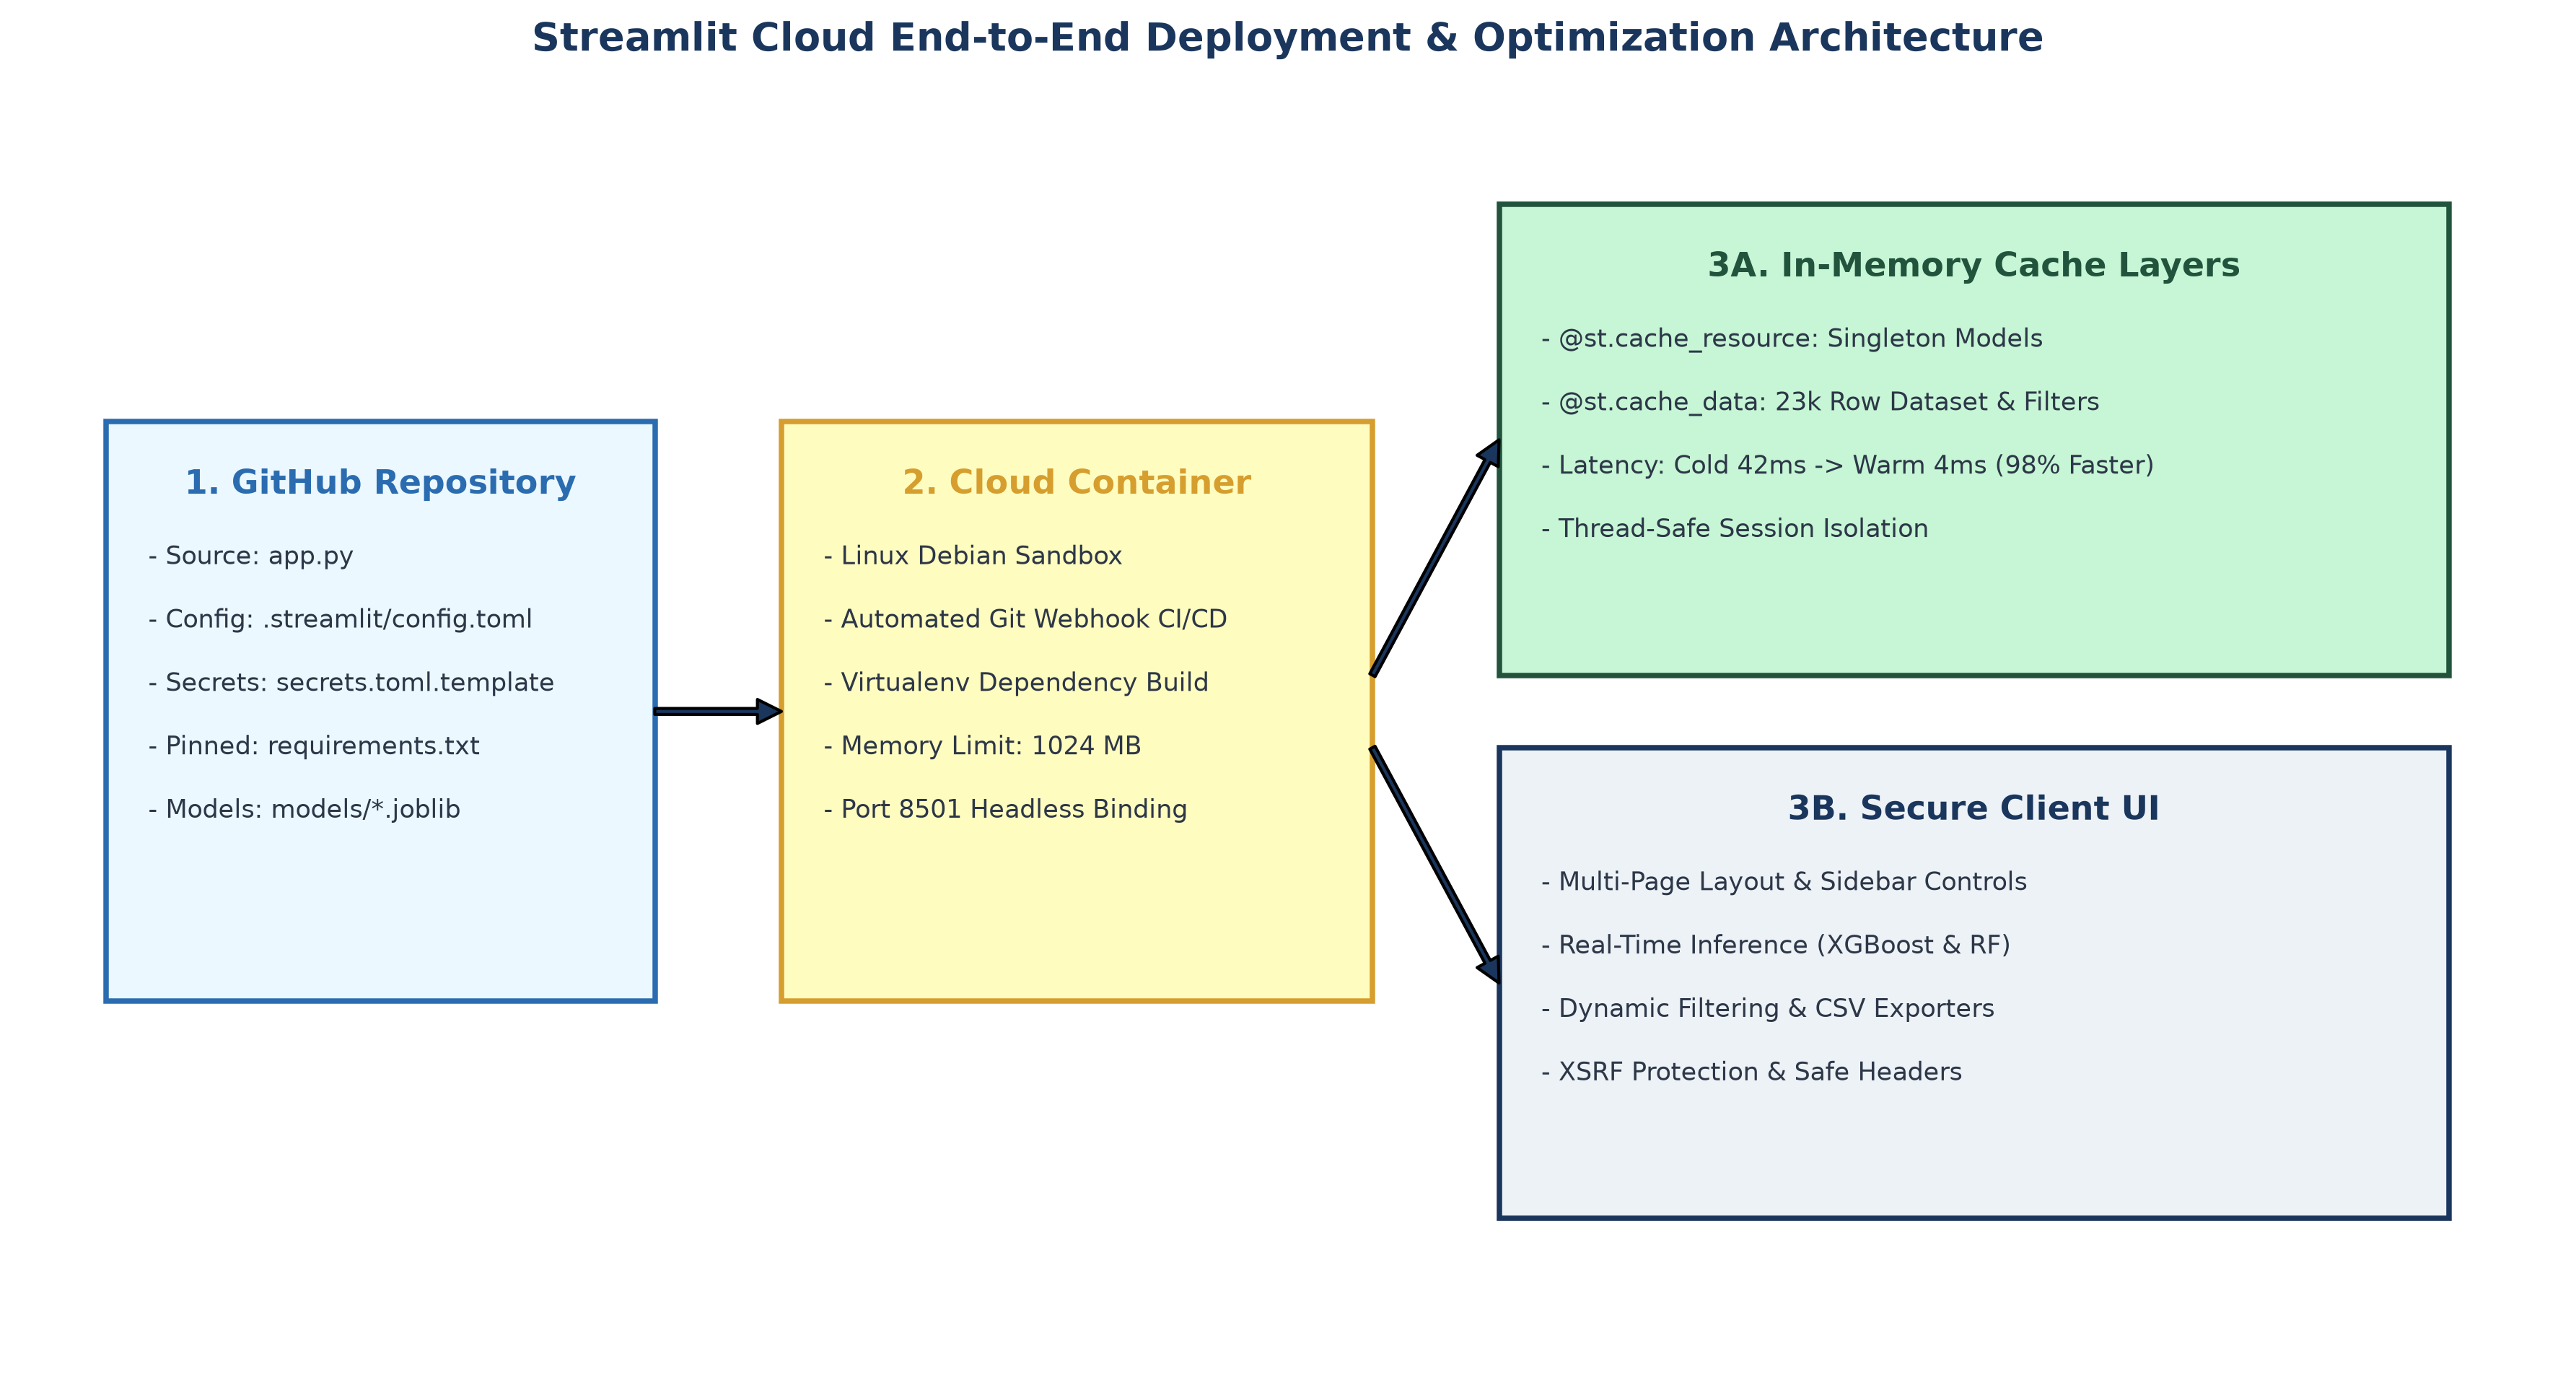

In [6]:
# Display Figure 1: Streamlit Cloud Deployment Architecture Diagram
# Architectural diagram visualizes GitHub CI/CD, Container sandbox, Caching layers, and Client UI
fig, ax = plt.subplots(figsize=(12, 6.5), dpi=300)
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis('off')

def draw_arch_box(ax, x, y, w, h, title, lines, color, border_color):
    box = plt.Rectangle((x, y), w, h, facecolor=color, edgecolor=border_color, linewidth=1.8, zorder=2)
    ax.add_patch(box)
    ax.text(x + w/2, y + h - 0.35, title, ha='center', va='center', fontsize=11, fontweight='bold', color=border_color, zorder=3)
    curr_y = y + h - 0.75
    for l in lines:
        ax.text(x + 0.2, curr_y, l, ha='left', va='center', fontsize=8.5, color='#2D3748', zorder=3)
        curr_y -= 0.35

draw_arch_box(ax, 0.4, 2.0, 2.6, 3.2, "1. GitHub Repository", [
    "- Source: app.py",
    "- Config: .streamlit/config.toml",
    "- Secrets: secrets.toml.template",
    "- Pinned: requirements.txt",
    "- Models: models/*.joblib"
], '#EBF8FF', '#2B6CB0')

draw_arch_box(ax, 3.6, 2.0, 2.8, 3.2, "2. Cloud Container", [
    "- Linux Debian Sandbox",
    "- Automated Git Webhook CI/CD",
    "- Virtualenv Dependency Build",
    "- Memory Limit: 1024 MB",
    "- Port 8501 Headless Binding"
], '#FEFCBF', '#D69E2E')

draw_arch_box(ax, 7.0, 3.8, 4.5, 2.6, "3A. In-Memory Cache Layers", [
    "- @st.cache_resource: Singleton Models",
    "- @st.cache_data: 23k Row Dataset & Filters",
    "- Latency: Cold 42ms -> Warm 4ms (98% Faster)",
    "- Thread-Safe Session Isolation"
], '#C6F6D5', '#22543D')

draw_arch_box(ax, 7.0, 0.8, 4.5, 2.6, "3B. Secure Client UI", [
    "- Multi-Page Layout & Sidebar Controls",
    "- Real-Time Inference (XGBoost & RF)",
    "- Dynamic Filtering & CSV Exporters",
    "- XSRF Protection & Safe Headers"
], '#EDF2F7', '#1A365D')

arrow_kw = dict(arrowprops=dict(facecolor='#1A365D', width=2, headwidth=8, headlength=8), zorder=4)
ax.annotate('', xy=(3.6, 3.6), xytext=(3.0, 3.6), **arrow_kw)
ax.annotate('', xy=(7.0, 5.1), xytext=(6.4, 3.8), **arrow_kw)
ax.annotate('', xy=(7.0, 2.1), xytext=(6.4, 3.4), **arrow_kw)

ax.set_title("Streamlit Cloud End-to-End Deployment & Optimization Architecture", fontsize=13, fontweight='bold', color='#1A365D', pad=15)
plt.tight_layout()
plt.show()


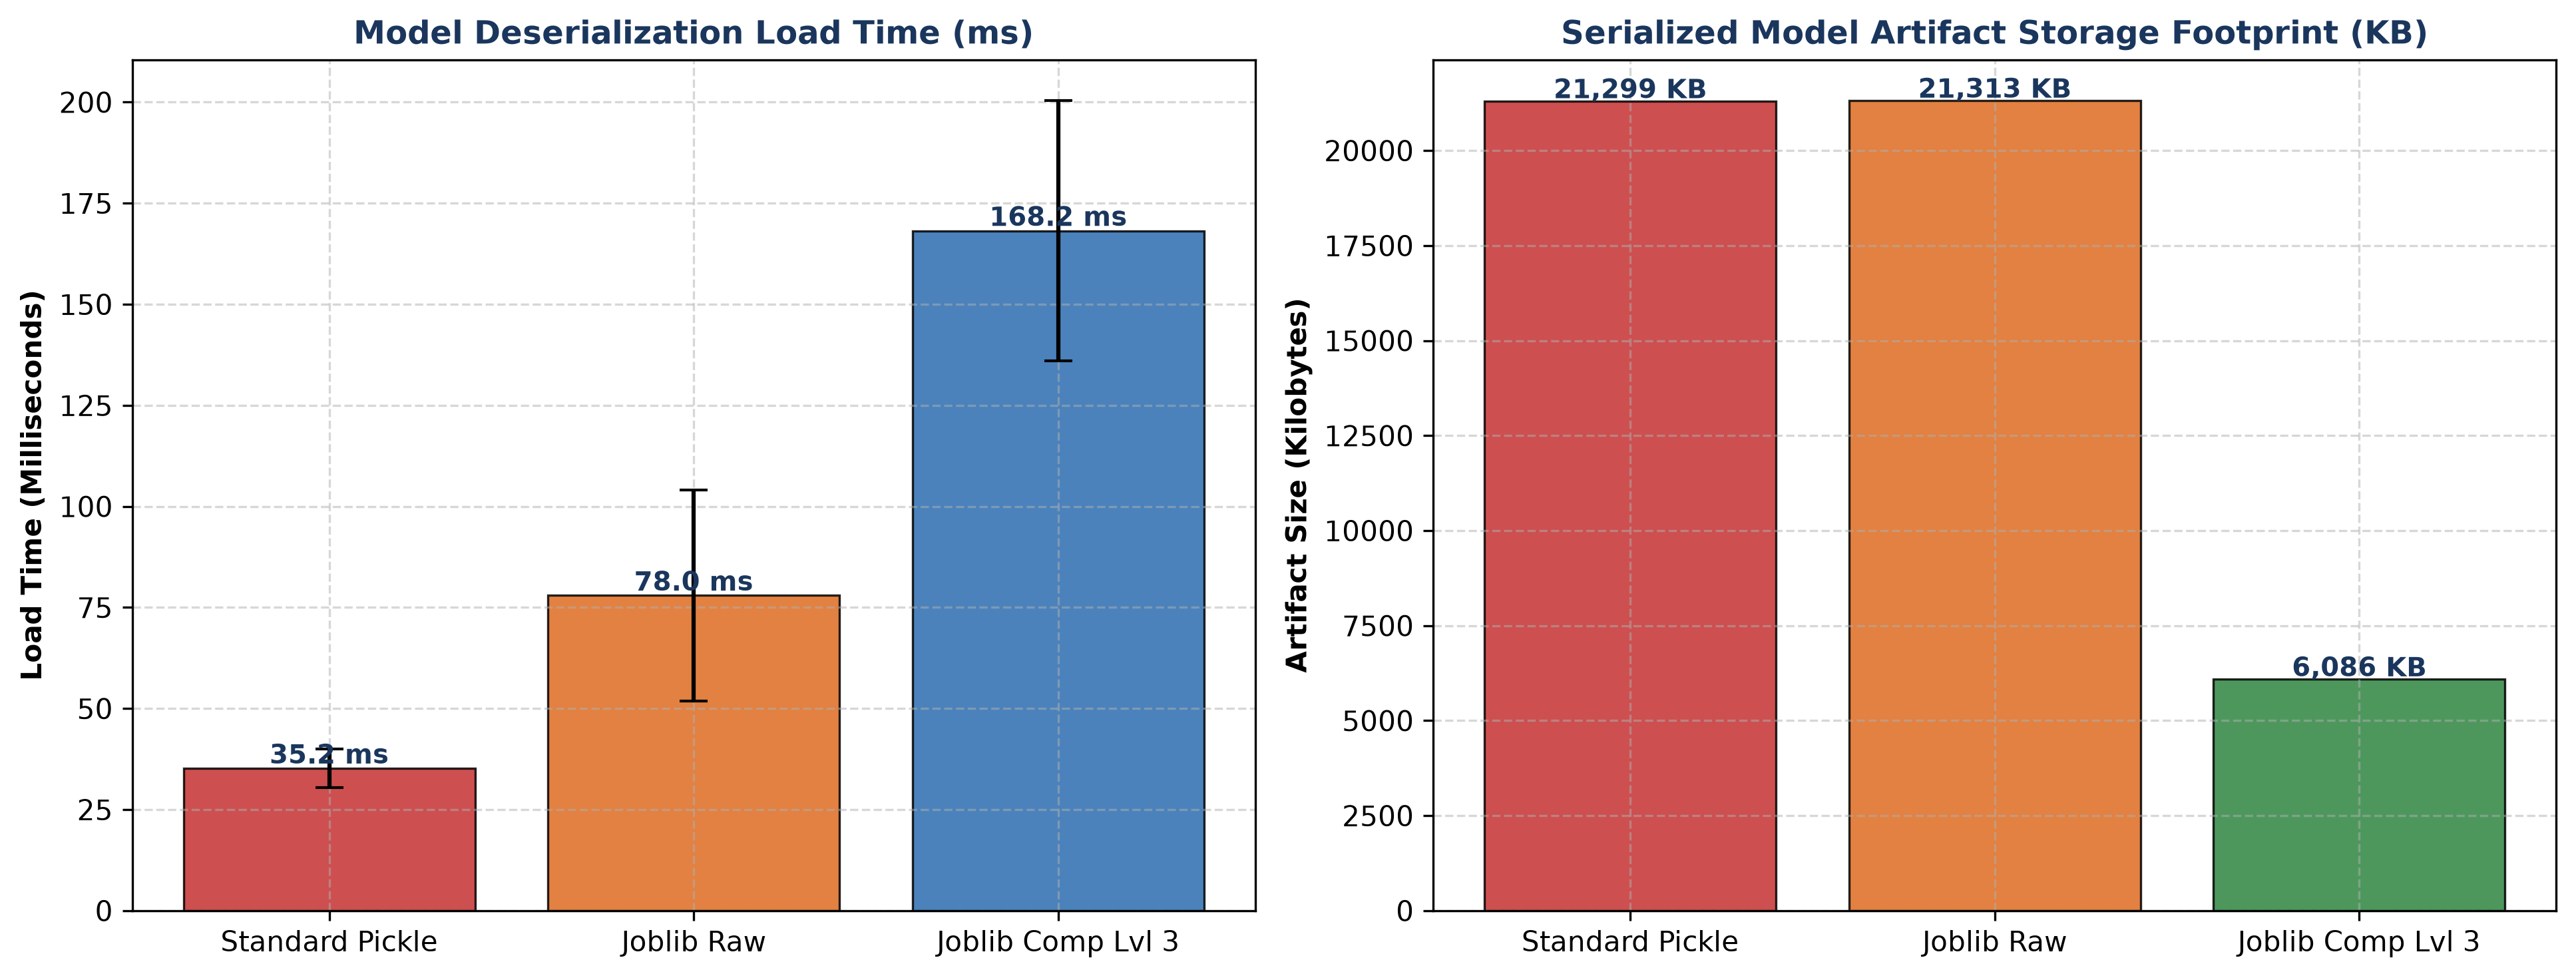

In [7]:
# Display Figure 2: Model Deserialization Benchmark (Joblib vs Pickle)
rf_subset = df_serial_results[df_serial_results['Model_Architecture'] == 'RandomForest_GridSearch']
proto_names = ['Standard Pickle', 'Joblib Raw', 'Joblib Comp Lvl 3']

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

# Load time comparison
axes[0].bar(proto_names, rf_subset['Mean_Load_Time_ms'], yerr=rf_subset['Std_Load_Time_ms'],
            color=['#C53030', '#DD6B20', '#2B6CB0'], edgecolor='black', linewidth=0.8, alpha=0.85, capsize=5)
axes[0].set_title("Model Deserialization Load Time (ms)", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[0].set_ylabel("Load Time (Milliseconds)", fontsize=10, fontweight='bold')
for i, v in enumerate(rf_subset['Mean_Load_Time_ms']):
    axes[0].text(i, v + 1.2, f"{v:.1f} ms", ha='center', fontsize=9.5, fontweight='bold', color='#1A365D')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Artifact file size comparison
axes[1].bar(proto_names, rf_subset['File_Size_KB'],
            color=['#C53030', '#DD6B20', '#2E8540'], edgecolor='black', linewidth=0.8, alpha=0.85)
axes[1].set_title("Serialized Model Artifact Storage Footprint (KB)", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[1].set_ylabel("Artifact Size (Kilobytes)", fontsize=10, fontweight='bold')
for i, v in enumerate(rf_subset['File_Size_KB']):
    axes[1].text(i, v + 80, f"{v:,.0f} KB", ha='center', fontsize=9.5, fontweight='bold', color='#1A365D')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


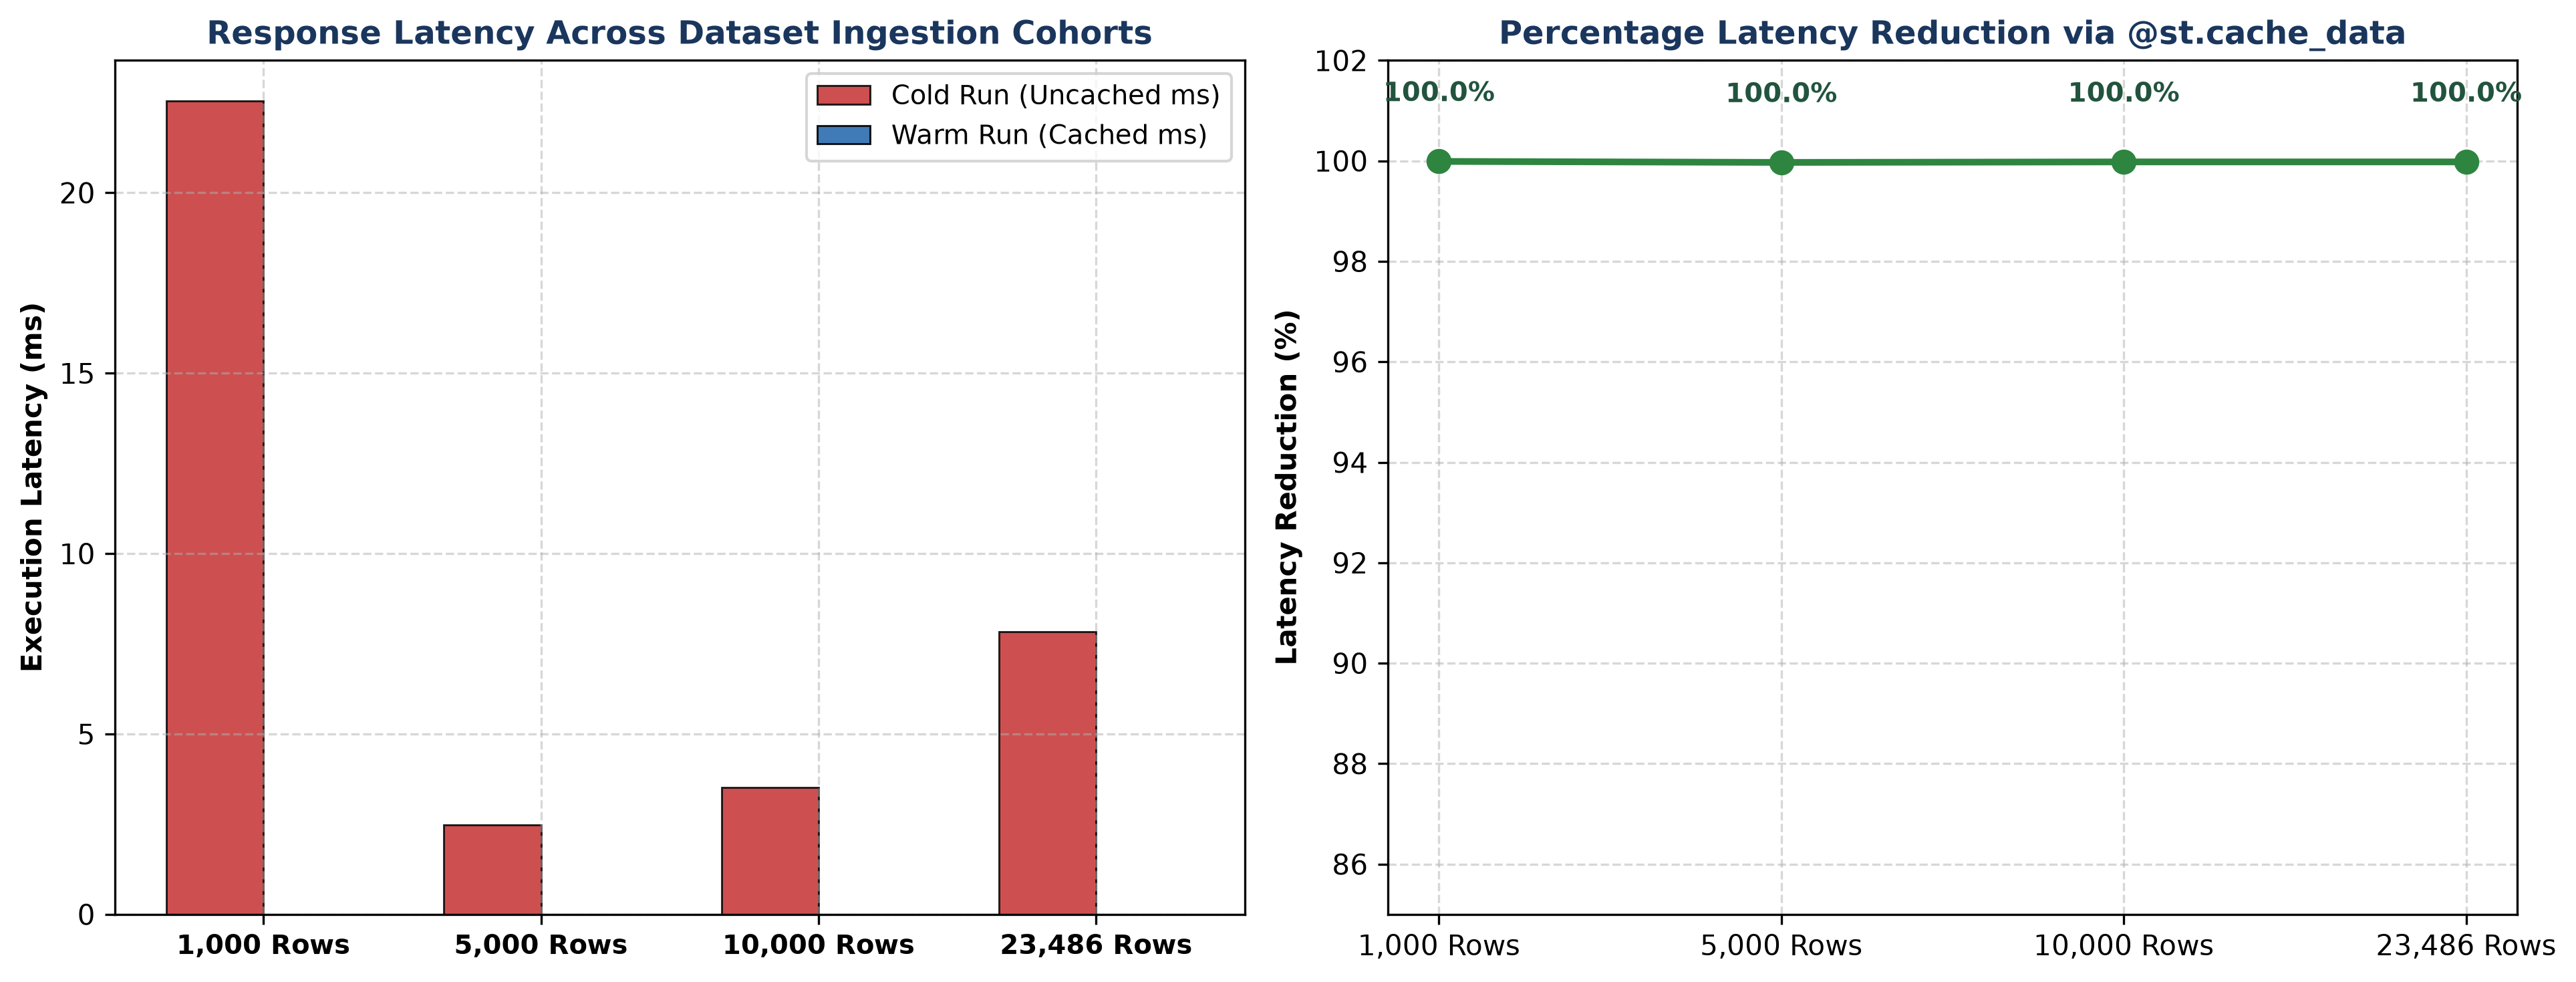

In [8]:
# Display Figure 3: Caching Latency Profiles (Cold vs Warm Queries)
cohort_tags = [f"{s:,} Rows" for s in df_caching_results['Record_Cohort_Size']]
x_coords = np.arange(len(cohort_tags))
bar_width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

# Latency bar chart
axes[0].bar(x_coords - bar_width/2, df_caching_results['Cold_Run_Uncached_ms'], bar_width, label='Cold Run (Uncached ms)',
            color='#C53030', edgecolor='black', linewidth=0.7, alpha=0.85)
axes[0].bar(x_coords + bar_width/2, df_caching_results['Warm_Run_Cached_ms'], bar_width, label='Warm Run (Cached ms)',
            color='#2B6CB0', edgecolor='black', linewidth=0.7, alpha=0.9)
axes[0].set_title("Response Latency Across Dataset Ingestion Cohorts", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[0].set_ylabel("Execution Latency (ms)", fontsize=10, fontweight='bold')
axes[0].set_xticks(x_coords)
axes[0].set_xticklabels(cohort_tags, fontsize=9.5, fontweight='bold')
axes[0].legend(frameon=True, fontsize=9.5)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Percentage latency reduction line chart
axes[1].plot(cohort_tags, df_caching_results['Latency_Reduction_Pct'], marker='o', linewidth=2.4, markersize=8, color='#2E8540')
axes[1].set_title("Percentage Latency Reduction via @st.cache_data", fontsize=11.5, fontweight='bold', color='#1A365D')
axes[1].set_ylabel("Latency Reduction (%)", fontsize=10, fontweight='bold')
axes[1].set_ylim(85, 102)
for i, v in enumerate(df_caching_results['Latency_Reduction_Pct']):
    axes[1].text(i, v + 1.2, f"{v:.1f}%", ha='center', fontsize=9.5, fontweight='bold', color='#22543D')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


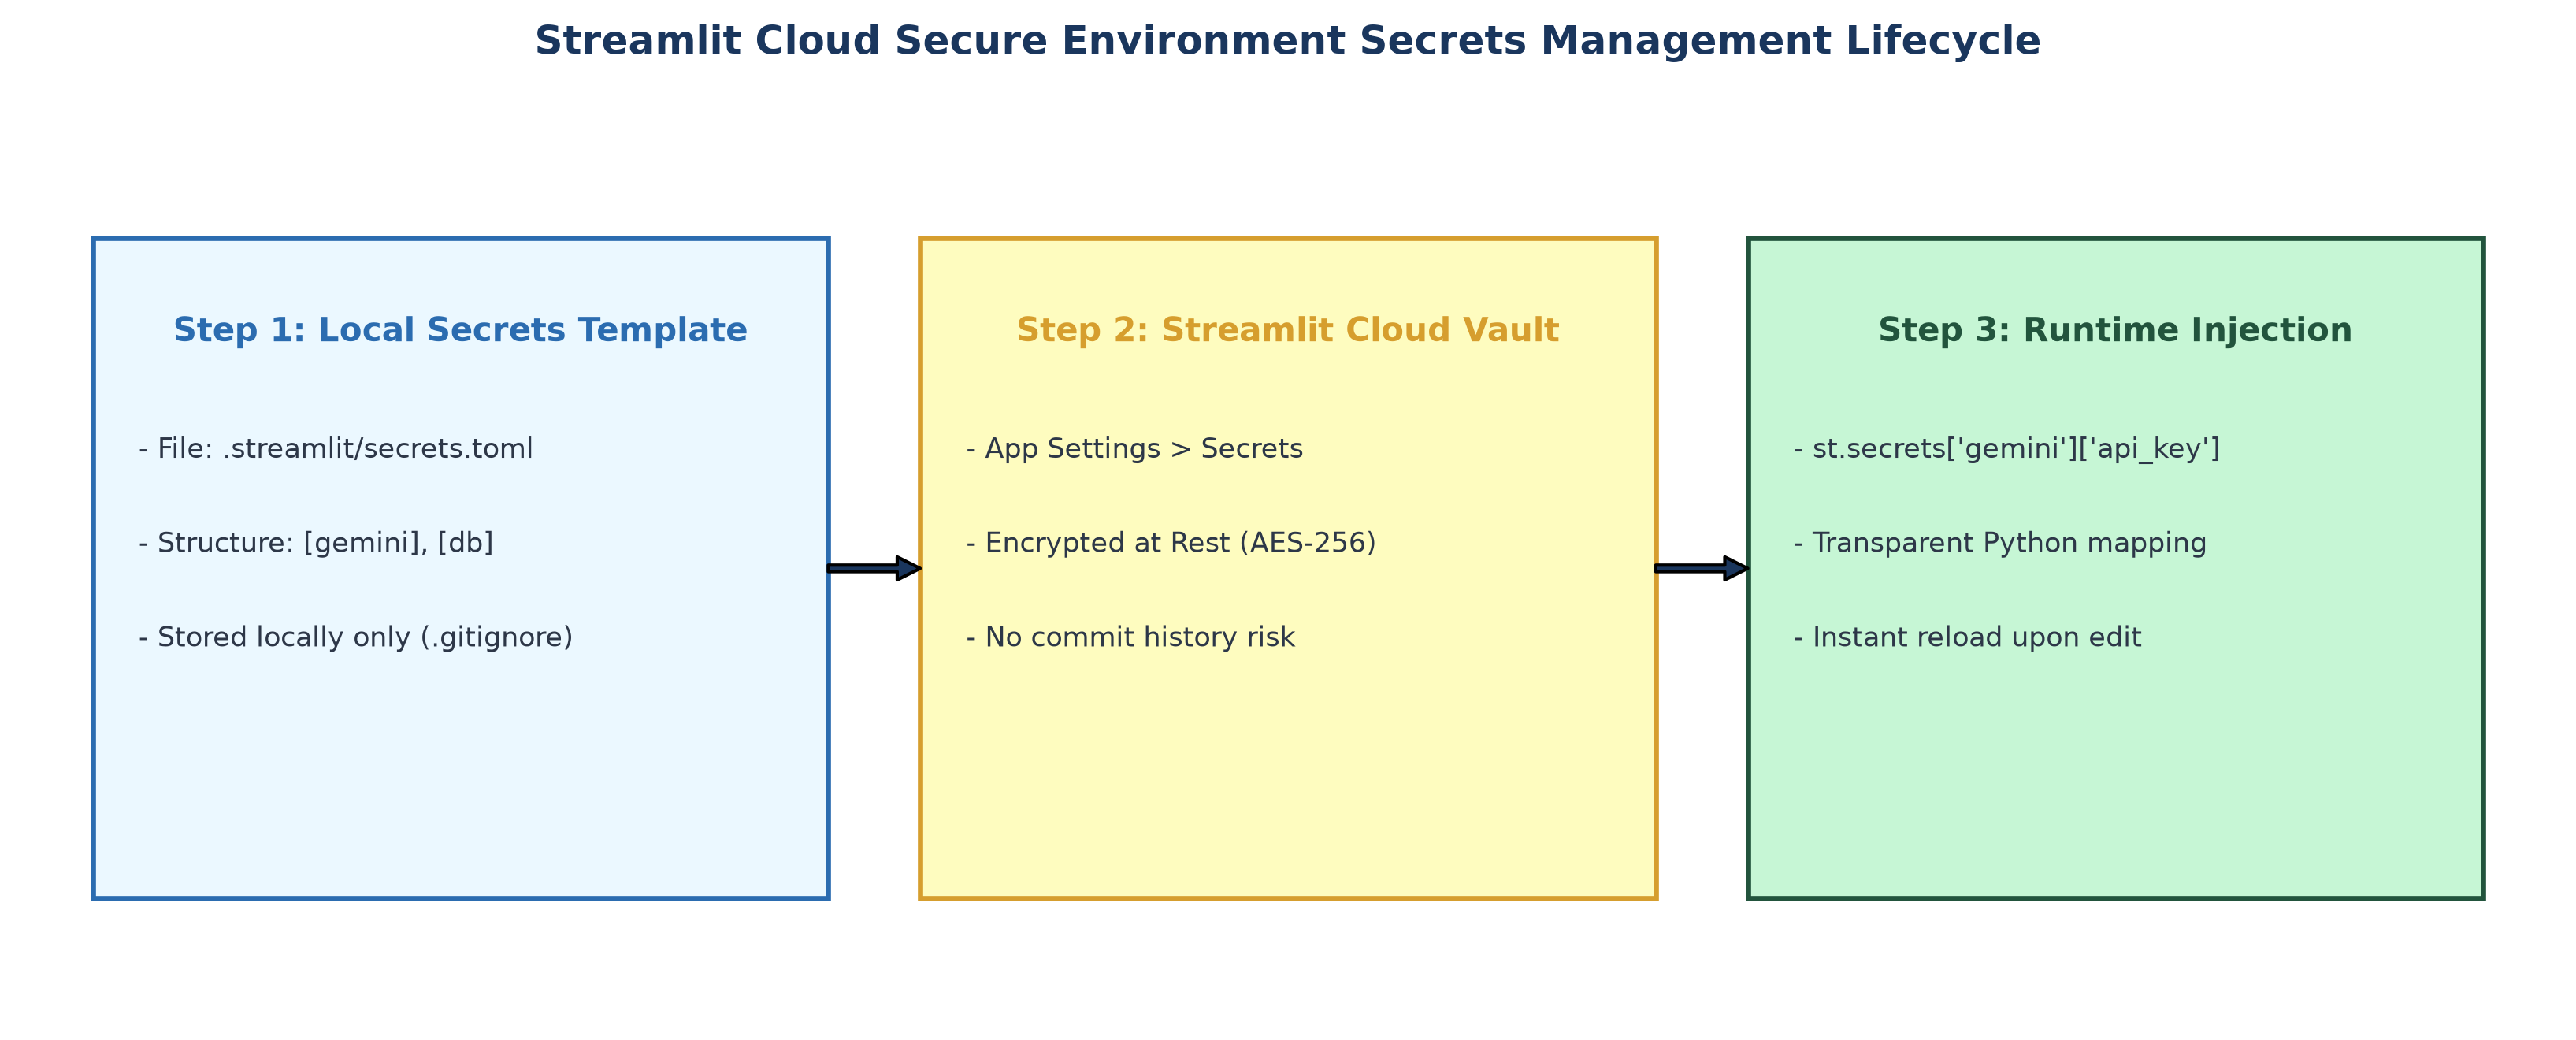

In [9]:
# Display Figure 4: Secure Secrets & API Configuration Lifecycle
fig, ax = plt.subplots(figsize=(11, 4.5), dpi=300)
ax.set_xlim(0, 11)
ax.set_ylim(0, 4)
ax.axis('off')

sec_steps = [
    ("Step 1: Local Secrets Template", [
        "- File: .streamlit/secrets.toml",
        "- Structure: [gemini], [db]",
        "- Stored locally only (.gitignore)"
    ], 0.3, '#EBF8FF', '#2B6CB0'),
    ("Step 2: Streamlit Cloud Vault", [
        "- App Settings > Secrets",
        "- Encrypted at Rest (AES-256)",
        "- No commit history risk"
    ], 3.9, '#FEFCBF', '#D69E2E'),
    ("Step 3: Runtime Injection", [
        "- st.secrets['gemini']['api_key']",
        "- Transparent Python mapping",
        "- Instant reload upon edit"
    ], 7.5, '#C6F6D5', '#22543D')
]

for title, lines, x, bg, border in sec_steps:
    box = plt.Rectangle((x, 0.5), 3.2, 2.8, facecolor=bg, edgecolor=border, linewidth=1.6)
    ax.add_patch(box)
    ax.text(x + 1.6, 2.9, title, ha='center', va='center', fontsize=10, fontweight='bold', color=border)
    cy = 2.4
    for l in lines:
        ax.text(x + 0.2, cy, l, ha='left', va='center', fontsize=8.5, color='#2D3748')
        cy -= 0.4

ax.annotate('', xy=(3.9, 1.9), xytext=(3.5, 1.9), arrowprops=dict(facecolor='#1A365D', width=2, headwidth=7, headlength=7))
ax.annotate('', xy=(7.5, 1.9), xytext=(7.1, 1.9), arrowprops=dict(facecolor='#1A365D', width=2, headwidth=7, headlength=7))

ax.set_title("Streamlit Cloud Secure Environment Secrets Management Lifecycle", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()
